Processing the LFW Dataset with a CNN  - <11/1/2026> - <abrgeb8774>

In [27]:
# Import necessary libraries
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_lfw_people
from datetime import datetime
from IPython.display import display, Markdown
todays_date = datetime.now().strftime("%Y-%m-%d")
student_id = "abrgeb8774"
# Load the LFW dataset
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
data = lfw_people.data
target = lfw_people.target
target_names = lfw_people.target_names
# Display dataset information
display(Markdown("### Load the Dataset"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
print(f"Data shape: {data.shape}")
print(f"Number of classes: {len(target_names)}")
print(f"Classes: {target_names}")

### Load the Dataset

Date: 2026-11-01

Student ID: abrgeb8774

Data shape: (1288, 1850)
Number of classes: 7
Classes: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Tony Blair']


In [28]:
# Import necessary libraries
import tensorflow as tf
from sklearn.model_selection import train_test_split
display(Markdown("### Preprocess the Data"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Normalize the pixel values
data = data / 255.0
# Add additional features if needed (e.g., pixel intensity statistics)
min_pixel_values = np.min(data, axis=1).reshape(-1, 1)
max_pixel_values = np.max(data, axis=1).reshape(-1, 1)
# Concatenate the new features with the original data
data_with_features = np.hstack((data, min_pixel_values, max_pixel_values))
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(data_with_features, target, test_size=0.3, random_state=42)
# Convert the target to categorical
y_train_cat = tf.keras.utils.to_categorical(y_train, len(target_names))
y_test_cat = tf.keras.utils.to_categorical(y_test, len(target_names))
# Display the shape of the training and testing data
print(f"Training data shape: {X_train.shape}")
print(f"Testing data shape: {X_test.shape}")
print(f"Training target shape: {y_train_cat.shape}")
print(f"Testing target shape: {y_test_cat.shape}")

### Preprocess the Data

Date: 2026-11-01

Student ID: abrgeb8774

Training data shape: (901, 1852)
Testing data shape: (387, 1852)
Training target shape: (901, 7)
Testing target shape: (387, 7)


In [29]:
# Import necessary libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
display(Markdown("### Building the TensorFlow Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Build the neural network model
model = Sequential([Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.5),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(7, activation='softmax')
])
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
# Display the model summary
model.summary()

### Building the TensorFlow Model

Date: 2026-11-01

Student ID: abrgeb8774

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_24 (Dense)                │ (None, 128)            │       237,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 7)              │           455 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 245,895 (960.53 KB)

 Trainable params: 245,895 (960.53 KB)

 Non-trainable params: 0 (0.00 B)

### Evaluate the CNN Model

Date: 2026-11-01

Student ID: abrgeb8774

13/13 - 1s - 44ms/step - accuracy: 0.0465 - loss: 1.9458
Test accuracy: 0.04651162773370743
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


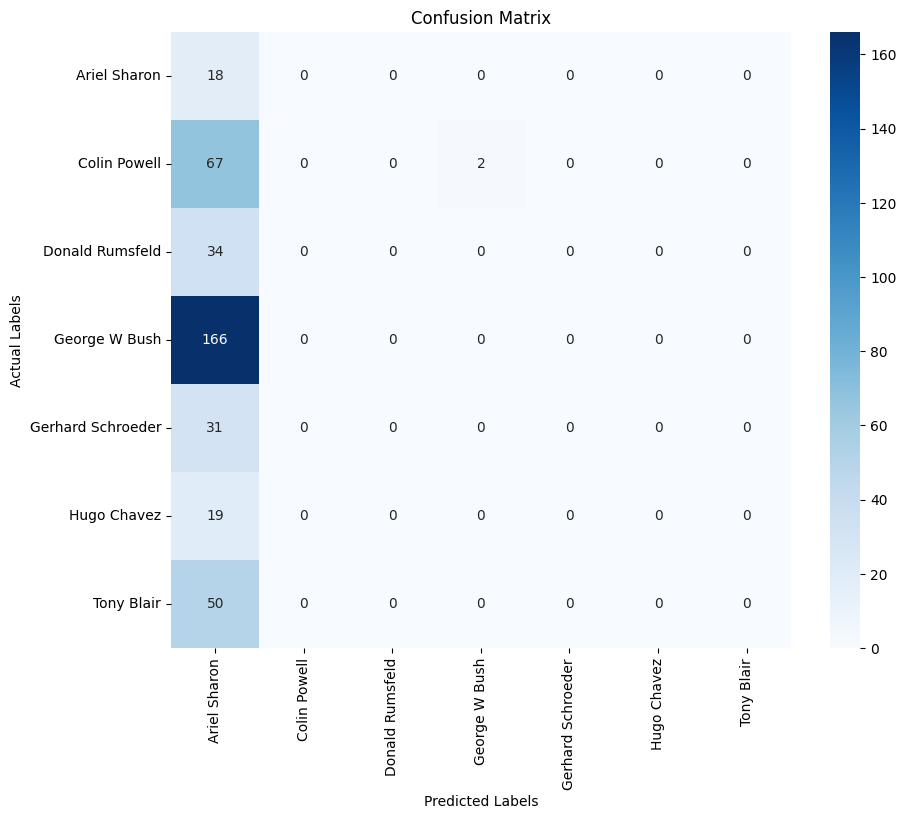

In [30]:
# Import necessary libraries
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
display(Markdown("### Evaluate the CNN Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Evaluate the model on the testing data
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=2)
print(f"Test accuracy: {test_acc}")
# Make predictions on the testing data
predictions = model.predict(X_test)
# Convert predictions to class labels
predicted_labels = np.argmax(predictions, axis=1)
# Create the confusion matrix
conf_matrix = confusion_matrix(y_test, predicted_labels)
# Display the confusion matrix heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix')
plt.ylabel('Actual Labels')
plt.xlabel('Predicted Labels')
plt.show()

In [31]:
from sklearn.decomposition import PCA
import numpy as np
display(Markdown("### Advanced Feature Engineering and Train the Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Apply PCA to reduce dimensionality
pca = PCA(n_components=150, whiten=True, random_state=42)
data_pca = pca.fit_transform(data)
# Calculate minimum and maximum pixel values
min_pixel_values = np.min(data_pca, axis=1).reshape(-1, 1)
max_pixel_values = np.max(data_pca, axis=1).reshape(-1, 1)
# Add minimum and maximum values as additional features
data_with_features = np.hstack(
    (data_pca, min_pixel_values, max_pixel_values)
)
print(f"New data shape with engineered features: {data_with_features.shape}")
# Split the adjusted data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    data_with_features, target, test_size=0.3, random_state=42
)
# Convert target values to categorical format
y_train_cat = tf.keras.utils.to_categorical(
    y_train, len(target_names)
)
y_test_cat = tf.keras.utils.to_categorical(
    y_test, len(target_names)
)
# Build the new neural network model
model = Sequential([
    Dense(256, activation='relu',
          input_shape=(data_with_features.shape[1],)), Dropout(0.5),
    Dense(128, activation='relu'), Dropout(0.5),
    Dense(7, activation='softmax')
])
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
# Display the model summary
model.summary()

### Advanced Feature Engineering and Train the Model

Date: 2026-11-01

Student ID: abrgeb8774

New data shape with engineered features: (1288, 152)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_27 (Dense)                │ (None, 256)            │        39,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 72,967 (285.03 KB)

 Trainable params: 72,967 (285.03 KB)

 Non-trainable params: 0 (0.00 B)

### Evaluate the Adjusted CNN Model

Date: 2026-11-01

Student ID: abrgeb8774

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.2694 - loss: 2.2599 - val_accuracy: 0.4254 - val_loss: 1.6215
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.3819 - loss: 1.7773 - val_accuracy: 0.4917 - val_loss: 1.5452
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4361 - loss: 1.6037 - val_accuracy: 0.4696 - val_loss: 1.4565
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5000 - loss: 1.4706 - val_accuracy: 0.5083 - val_loss: 1.3848
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5236 - loss: 1.3440 - val_accuracy: 0.5470 - val_loss: 1.3231
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.5778 - loss: 1.1699 - val_accuracy: 0.5912 - val_loss: 1.2235
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6458 - loss: 1.0374 - val_accuracy: 0.6685 - val_loss: 1.1106
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6861 - loss: 0.8961 - val_accuracy: 0.6961 - val_loss

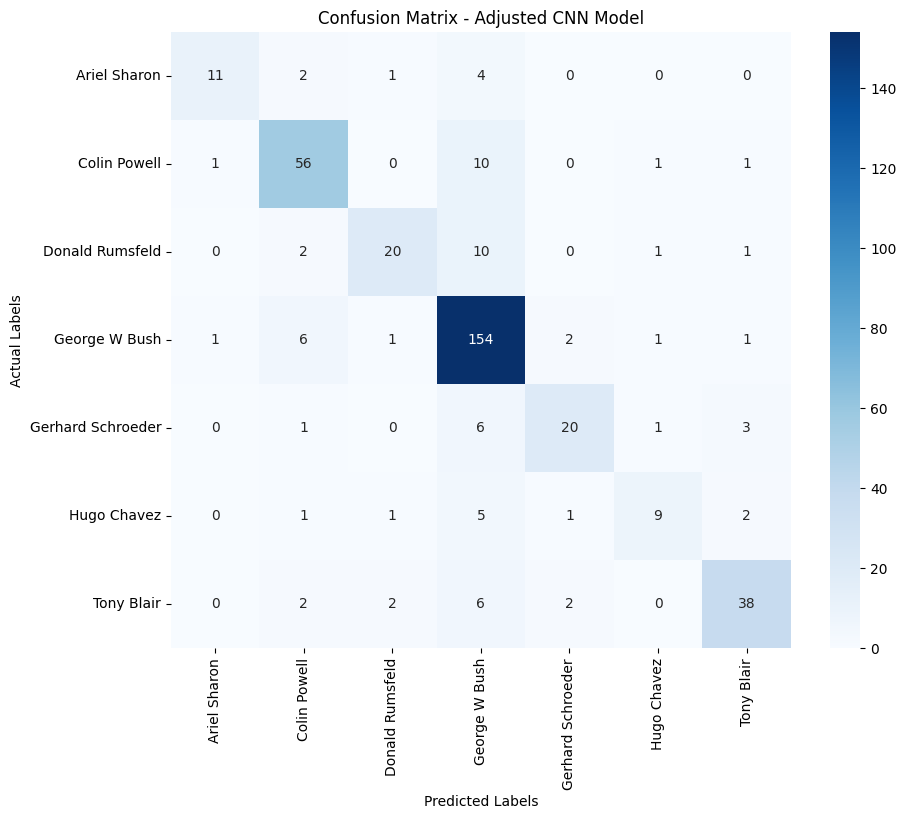

In [32]:
display(Markdown("### Evaluate the Adjusted CNN Model"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Train the adjusted model
history = model.fit(X_train, y_train_cat, epochs=20, batch_size=32, validation_split=0.2)
# Evaluate the model using the test data
test_loss, test_acc = model.evaluate(X_test, y_test_cat, verbose=2)
print(f"Test accuracy: {test_acc}")
# Predict the test data
predictions = model.predict(X_test)
# Convert predictions to class labels
predicted_labels = np.argmax(predictions, axis=1)
# Create the confusion matrix
conf_matrix = confusion_matrix(y_test, predicted_labels)
# Display the confusion matrix heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix - Adjusted CNN Model')
plt.ylabel('Actual Labels')
plt.xlabel('Predicted Labels')
plt.show()

### Compare Performance of the CNN Models

Date: 2026-11-01

Student ID: abrgeb8774

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.2097 - loss: 2.4291 - val_accuracy: 0.4033 - val_loss: 1.7591
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.2833 - loss: 2.1252 - val_accuracy: 0.4199 - val_loss: 1.6928
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3375 - loss: 1.8171 - val_accuracy: 0.4144 - val_loss: 1.6733
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.3667 - loss: 1.7408 - val_accuracy: 0.4254 - val_loss: 1.6368
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4042 - loss: 1.6321 - val_accuracy: 0.4309 - val_loss: 1.5957
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4097 - loss: 1.5897 - val_accuracy: 0.4365 - val_loss: 1.5467
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.4500 - loss: 1.4946 - val_accuracy: 0.4365 - val_loss: 1.5026
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.4597 - loss: 1.4935 - val_accuracy: 0.4586 - val_loss

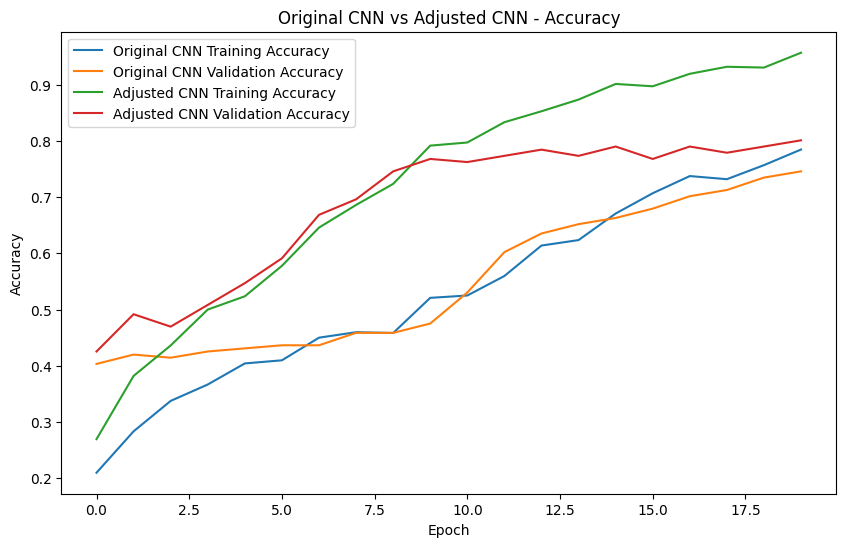

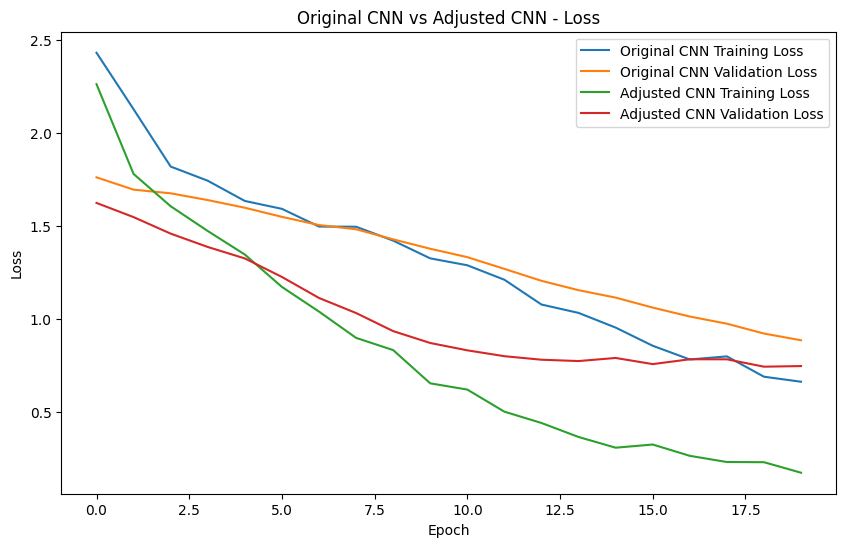

In [34]:
display(Markdown("### Compare Performance of the CNN Models"))
display(Markdown(f"Date: {todays_date}"))
display(Markdown(f"Student ID: {student_id}"))
# Build the original CNN model
original_model = Sequential([
    Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    Dropout(0.5), Dense(64, activation='relu'),
    Dropout(0.5), Dense(7, activation='softmax')
])
# Compile the original CNN model
original_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
# Train the original CNN model and save its history
original_history = original_model.fit(X_train, y_train_cat, epochs=20, batch_size=32, validation_split=0.2)
# Compare the accuracy of the original and adjusted models
plt.figure(figsize=(10, 6))
plt.plot(original_history.history['accuracy'], label='Original CNN Training Accuracy')
plt.plot(original_history.history['val_accuracy'], label='Original CNN Validation Accuracy')
plt.plot(history.history['accuracy'], label='Adjusted CNN Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Adjusted CNN Validation Accuracy')
plt.title('Original CNN vs Adjusted CNN - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()
# Compare the loss of the original and adjusted models
plt.figure(figsize=(10, 6))
plt.plot(original_history.history['loss'], label='Original CNN Training Loss')
plt.plot(original_history.history['val_loss'], label='Original CNN Validation Loss')
plt.plot(history.history['loss'], label='Adjusted CNN Training Loss')
plt.plot(history.history['val_loss'], label='Adjusted CNN Validation Loss')
plt.title('Original CNN vs Adjusted CNN - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()